ASSIGNMENT 1                                                           

Understanding Generative and Discriminative Models Using MNIST






In [ ]:
#Step 1: Import Required Libraries

import numpy as np
import matplotlib.pyplot as plt

from tensorflow.keras.datasets import mnist
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

In [ ]:
#Step 2: Load the MNIST Dataset
(X_train, y_train), (X_test, y_test) = mnist.load_data()

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)


In [ ]:
# Select only 0 and 1
train_filter = (y_train == 0) | (y_train == 1)
test_filter = (y_test == 0) | (y_test == 1)

X_train = X_train[train_filter]
y_train = y_train[train_filter]

X_test = X_test[test_filter]
y_test = y_test[test_filter]

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (12665, 28, 28)
Testing data: (2115, 28, 28)


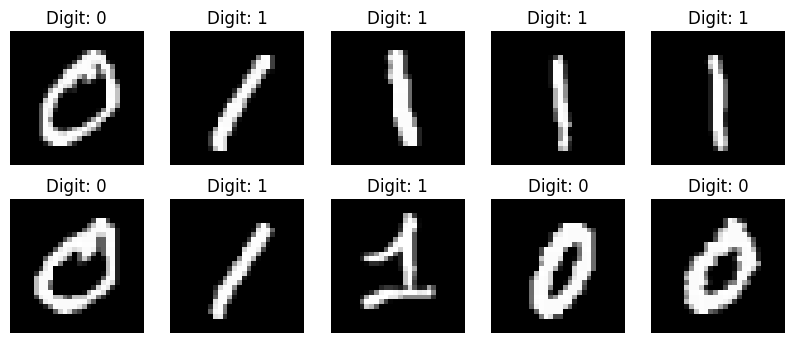

In [ ]:
#Step 4: Display the MNIST Images
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap="gray")
    plt.title("Digit: " + str(y_train[i]))
    plt.axis("off")

plt.show()

In [ ]:
#Step 5: Prepare Data for Logistic Regression
# Convert 28x28 images into 784 pixels
X_train_flat = X_train.reshape(X_train.shape[0], 784)
X_test_flat = X_test.reshape(X_test.shape[0], 784)

# Normalize pixel values from 0-255 to 0-1
X_train_flat = X_train_flat / 255.0
X_test_flat = X_test_flat / 255.0

print("Training data shape:", X_train_flat.shape)
print("Testing data shape:", X_test_flat.shape)

Training data shape: (12665, 784)
Testing data shape: (2115, 784)


In [ ]:
#Step 6: Create the Discriminative Model
model = LogisticRegression(max_iter=1000)

model.fit(X_train_flat, y_train)

print("Model training completed!")

Model training completed!


In [ ]:
#Step 7: Check the Model Accuracy
y_pred = model.predict(X_test_flat)

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy (%):", accuracy * 100)

Accuracy: 0.9995271867612293
Accuracy (%): 99.95271867612293


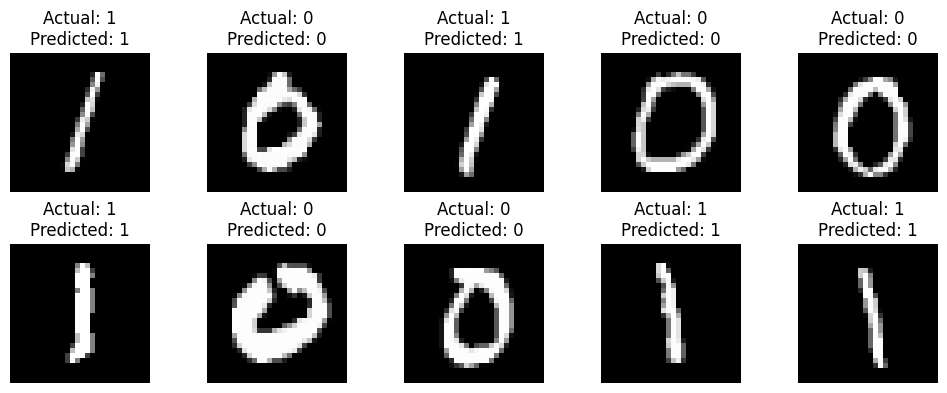

In [ ]:
#Step 8: Visualize Predictions
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i], cmap="gray")
    plt.title("Actual: " + str(y_test[i]) +
              "\nPredicted: " + str(y_pred[i]))
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
#Step 9: Prepare Data for the Generative Model
# Normalize the images
X_auto = X_train.astype("float32") / 255.0

print("Autoencoder data shape:", X_auto.shape)

Autoencoder data shape: (12665, 28, 28)


In [ ]:
#Step 10: Create the Autoencoder
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense, Reshape

autoencoder = Sequential([
    Flatten(input_shape=(28, 28)),

    # Encoder
    Dense(128, activation="relu"),
    Dense(32, activation="relu"),

    # Decoder
    Dense(128, activation="relu"),
    Dense(784, activation="sigmoid"),

    Reshape((28, 28))
])

autoencoder.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)

autoencoder.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_1 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 784)            │       101,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 28, 28)         │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 209,968 (820.19 KB)

 Trainable params: 209,968 (820.19 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
#Step 11: Train the Autoencoder
history = autoencoder.fit(
    X_auto,
    X_auto,
    epochs=10,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/10
90/90 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - loss: 0.2622 - val_loss: 0.1496
Epoch 2/10
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.1361 - val_loss: 0.1259
Epoch 3/10
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.1191 - val_loss: 0.1124
Epoch 4/10
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.1076 - val_loss: 0.1025
Epoch 5/10
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0986 - val_loss: 0.0942
Epoch 6/10
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0920 - val_loss: 0.0895
Epoch 7/10
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0879 - val_loss: 0.0873
Epoch 8/10
90/90 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 0.0848 - val_loss: 0.0838
Epoch 9/10
90/90 ━━━━━━━━━━━━━━━━━━━━ 2s 14ms/step - loss: 0.0823 - val_loss: 0.0819
Epoch 10/10
90/90 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0806 - val_loss: 0.0807


In [ ]:
#Step 12: Generate/Reconstruct Images
generated_images = autoencoder.predict(X_auto[:10])

print("Images generated successfully!")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 355ms/step
Images generated successfully!


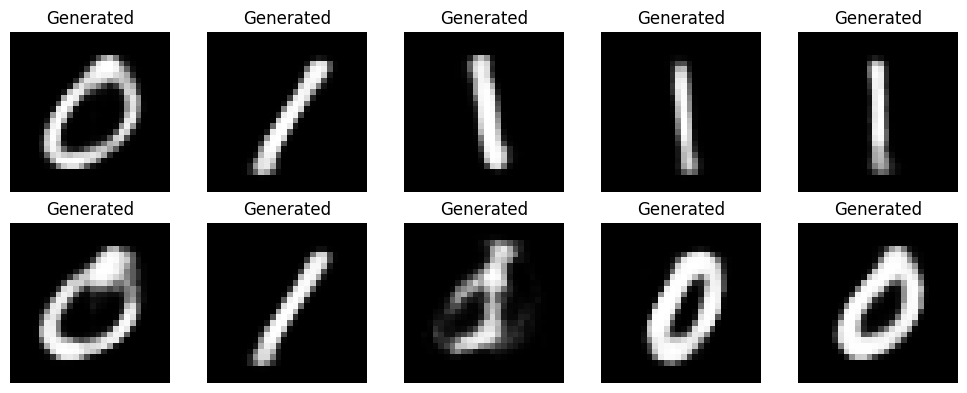

In [ ]:
#Step 13: Display Generated Images
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(generated_images[i], cmap="gray")
    plt.title("Generated")
    plt.axis("off")

plt.tight_layout()
plt.show()

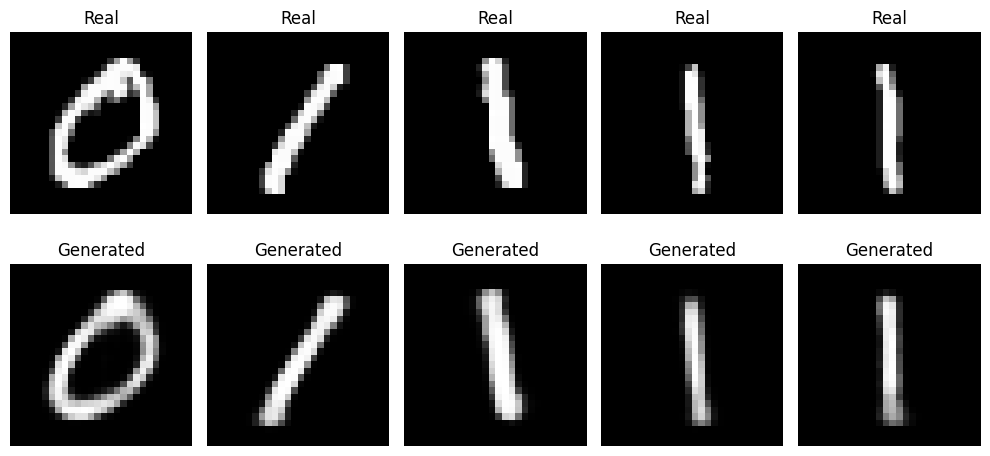

In [ ]:
#Step 14: Compare Real vs Generated Images
plt.figure(figsize=(10, 5))

for i in range(5):
    # Real image
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_auto[i], cmap="gray")
    plt.title("Real")
    plt.axis("off")

    # Generated image
    plt.subplot(2, 5, i + 6)
    plt.imshow(generated_images[i], cmap="gray")
    plt.title("Generated")
    plt.axis("off")

plt.tight_layout()
plt.show()

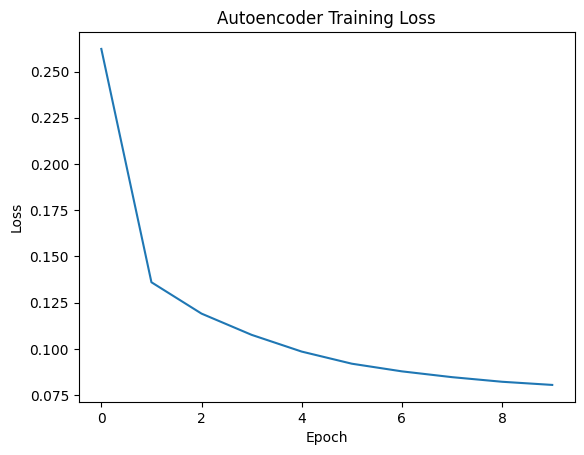

In [ ]:
#Step 15: Show Autoencoder Training Loss
plt.plot(history.history["loss"])
plt.title("Autoencoder Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.show()

### Final Comparison

| Model                | Purpose                                       | Output                          |
| -------------------- | --------------------------------------------- | ------------------------------- |
| Discriminative Model | Classifies handwritten digits                 | 0 or 1                          |
| Generative Model     | Learns patterns and reconstructs digit images | Geniserated/reconstructed image |

### Written Reflection

The discriminative model learned the differences between handwritten 0 and 1 images and used these differences to classify new images. The generative model learned the important patterns and features present in the digit images and reconstructed similar images. The main difference is that the discriminative model learns a decision boundary for classification, while the generative model learns the structure and patterns of the data. Therefore, the discriminative model is useful for classification, while the generative model is useful for learning and producing similar data.
